In [16]:
import numpy as np
import matplotlib.pyplot as plt

import polyfit
from polyfit import samples, PointSet, build_point_sets, attempt_fits
from polyfit.plotting import plot_points, plot_fit, plot_attempt, plot_pointset, subplot_grid

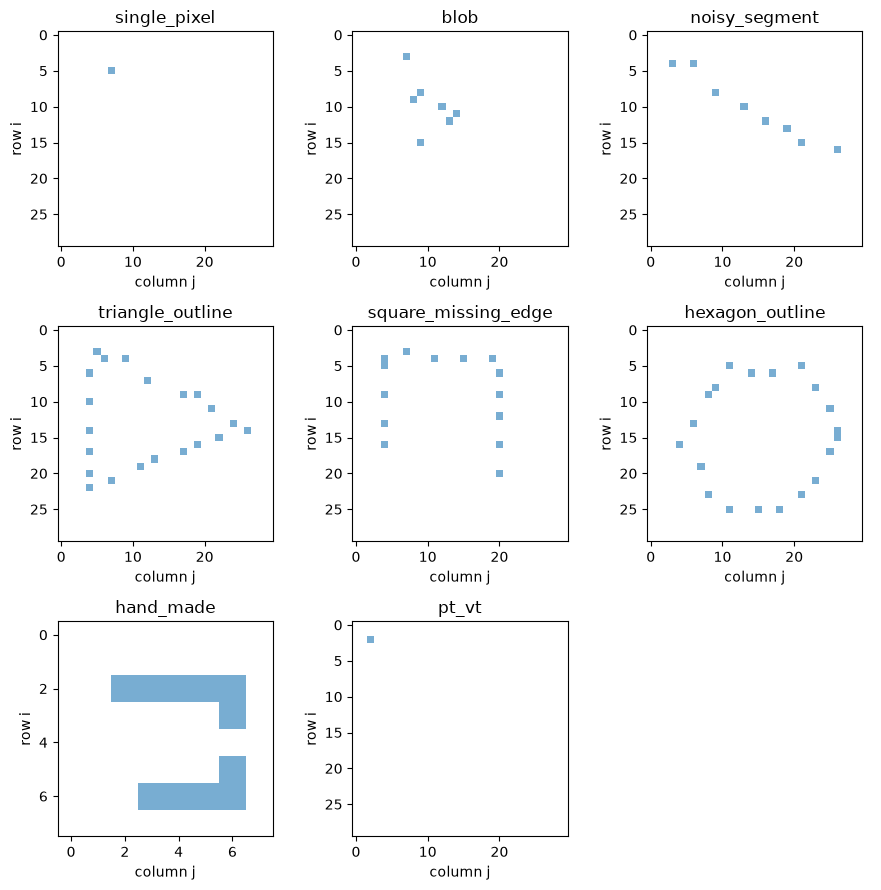

In [17]:
# load up some sets of points, located in samples.ALL
raw_points = {name: make() for name, make in samples.ALL.items()}

# add in a by-hand sample
my_pts = np.array([
    [2, 2], [2, 3], [2, 4], [2, 5], [2, 6],
    [3, 6], [5, 6], [6, 6],
    [6, 5], [6, 4], [6, 3]
])
my_pt = np.array([
    [2, 2]
])
raw_points["hand_made"] = my_pts
raw_points["pt_vt"] = my_pt


# Display the sets
names = list(raw_points)
fig, axes = subplot_grid(len(names))
for ax, name in zip(axes, names):
    shape = (8, 8) if name == "hand_made" else (30, 30)
    plot_points(raw_points[name], ax=ax, shape=shape, title=name)
fig.tight_layout()

## Create a dataclass object for each of the sets ##

2 failures:
 Failure at single_pixel: need at least 2 distinct points, got 1. No object created for this point set.
 Failure at pt_vt: need at least 2 distinct points, got 1. No object created for this point set.


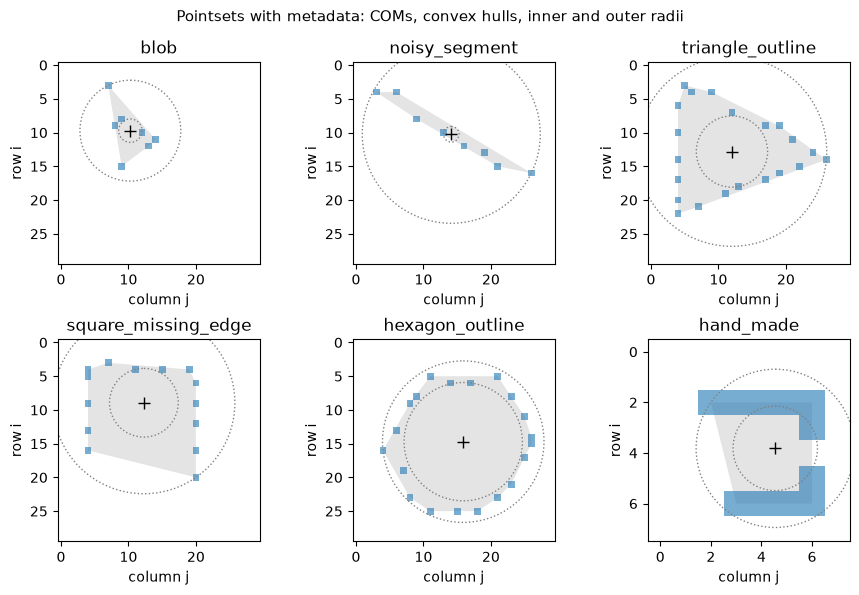

In [18]:
#
# Every set of points in raw_points gets its own object, of class PointSet
#
# Into the object goes the set of points itself, and various metadata for the point set (COM, diameter, inner radius, etc),
# Later, it will contain the polygon fitting attempts.
#
# "point_sets" contains a Python list of the dataclasses created.
# "failures" records any error codes, which happen when a point set fails to create a PointSet dataclass for some reason.

point_sets, failures = build_point_sets(raw_points)

if len(failures):
    print(f"{len(failures)} failures:")
    for key, value in failures.items():
        print(f" Failure at {key}: {value}. No object created for this point set.")

# Display each point set with some of its metadata: the convex hull (shaded gray, in the
# background), the inner and outer radius about the centre of mass (dotted circles), and
# the centre of mass itself (small cross). Only sets that became PointSets have metadata.
from matplotlib.patches import Circle, Polygon

fig, axes = subplot_grid(len(point_sets))
for ax, (name, ps) in zip(axes, point_sets.items()):
    shape = (8, 8) if name == "hand_made" else (30, 30)
    plot_points(ps.points, ax=ax, shape=shape, title=name)
    ci, cj = float(ps.com[0]), float(ps.com[1])                   # (row, column) of the centre of mass
    hull_xy = ps.hull[:, ::-1]                                    # (column, row) = (x, y) for matplotlib
    ax.add_patch(Polygon(hull_xy, closed=True, facecolor="lightgray", edgecolor="none",
                         alpha=0.6, zorder=0))
    for radius in (ps.inner_radius, ps.outer_radius):
        ax.add_patch(Circle((cj, ci), radius, fill=False, linestyle=":", color="gray"))
    ax.plot([cj], [ci], "+", color="black", markersize=8)
fig.suptitle("Pointsets with metadata: COMs, convex hulls, inner and outer radii", fontsize=11)
fig.tight_layout()

## Create the plans for each fitting attempt ##

In [19]:
# every set gets a segment fit
plans = {name: [dict(n_vertices=2)] for name in point_sets}

# additional fit attempts for various sets
plans["noisy_segment"] += [dict(n_vertices=2, engine="mock")]
plans["triangle_outline"] += [dict(n_vertices=3), dict(n_vertices=3, engine="mock")]
plans["square_missing_edge"] += [dict(n_vertices=4, missing_edges=[], engine="lean")]
plans["square_missing_edge"] += [dict(n_vertices=4, missing_edges=[2], engine="lean")]
plans["square_missing_edge"] += [dict(n_vertices=4, missing_edges=[0,2], engine="lean")]
plans["square_missing_edge"] += [dict(n_vertices=3, missing_edges=[], engine="lean")]
plans["square_missing_edge"] += [dict(n_vertices=4, missing_edges=[2], engine="mock")]
plans["hexagon_outline"] += [dict(n_vertices=6, missing_edges=[0], engine="lean")]
plans["hexagon_outline"] += [dict(n_vertices=6, missing_edges=[], engine="lean")]
plans["hexagon_outline"] += [dict(n_vertices=6, missing_edges=[], engine="mock")]
plans["blob"] += [dict(n_vertices=3, missing_edges=[], engine="mock")]
plans["blob"] += [dict(n_vertices=3, missing_edges=[], engine="lean")]
plans["blob"] += [dict(n_vertices=3, missing_edges=[1], engine="lean")]
plans["hand_made"] += [dict(n_vertices=4, missing_edges=[0], engine="lean")]

## Perform the polygon fitting on each point set, according to its plan(s) ##

stopped: none


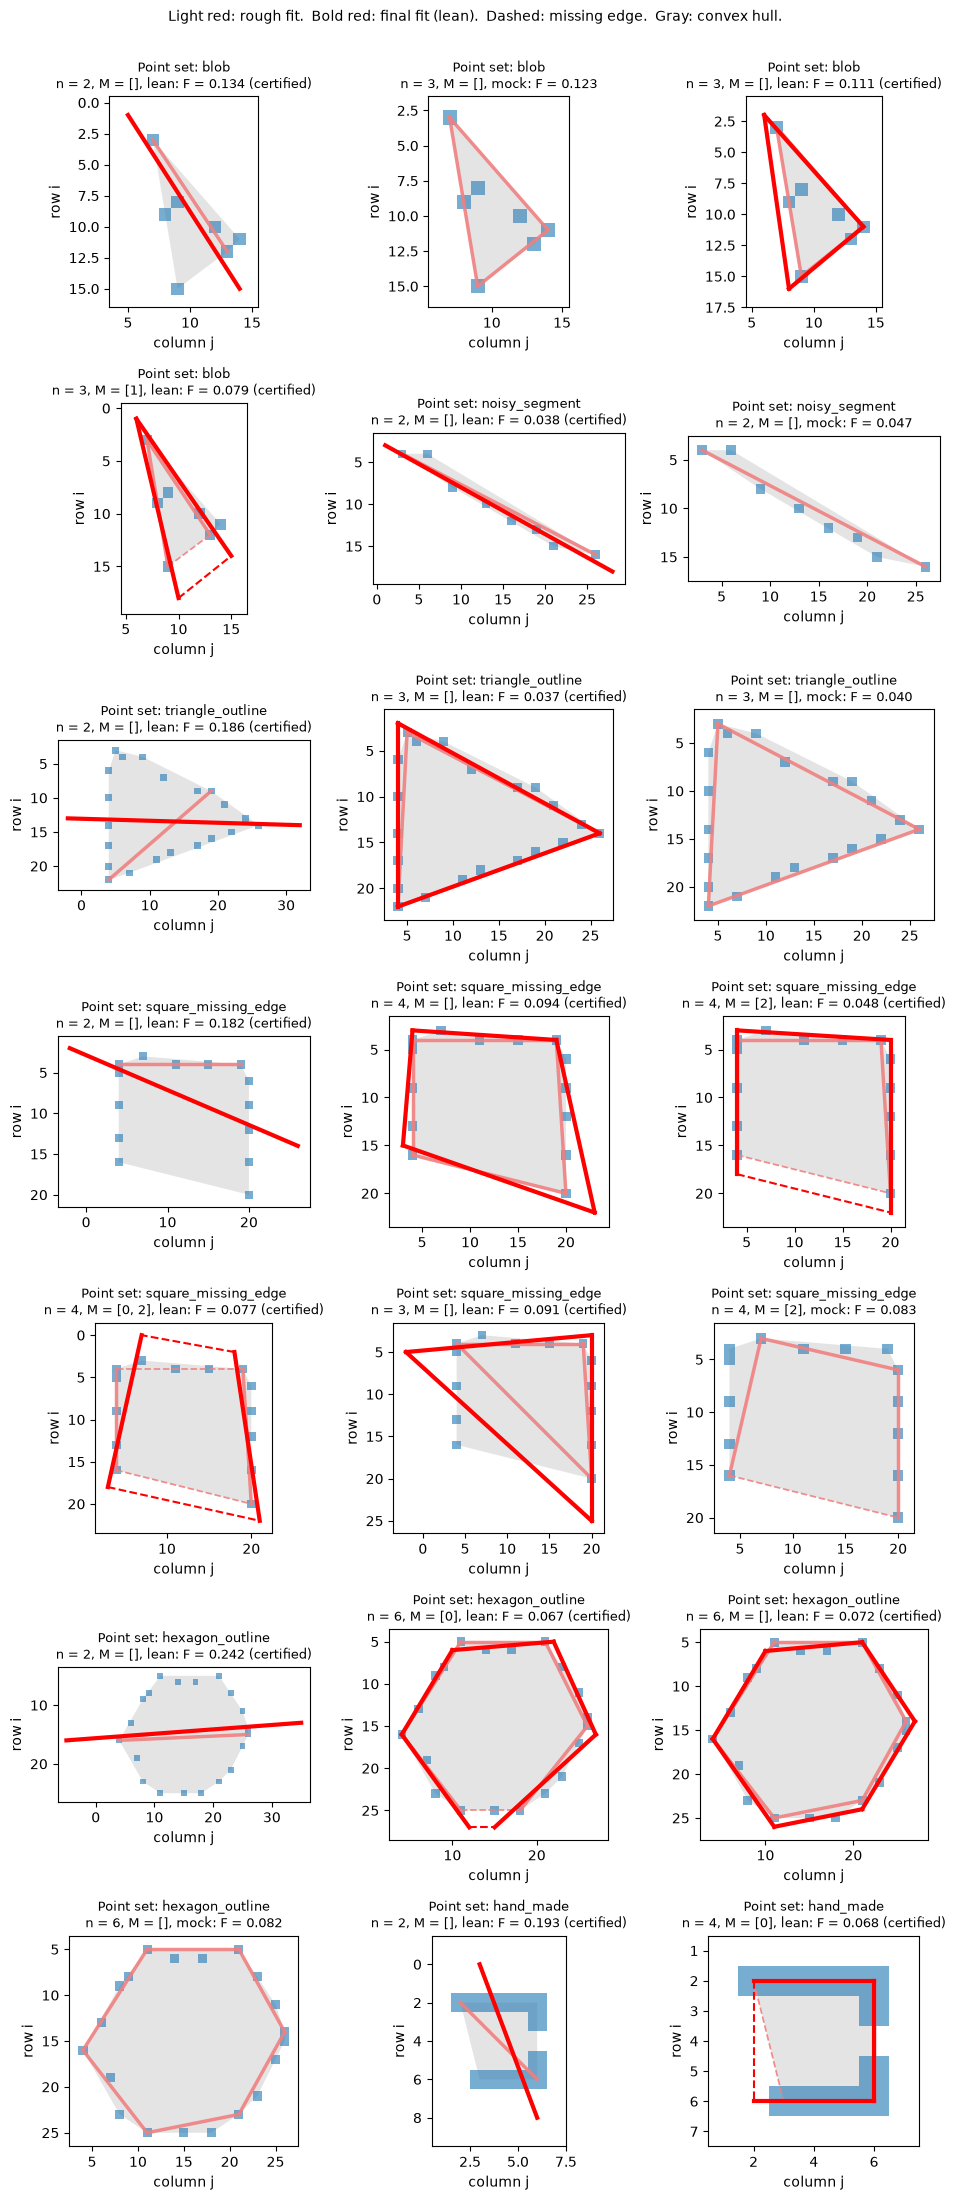

In [20]:
# Perform the fitting on each pointset, according to all of its plans
stopped = attempt_fits(point_sets, plans)

# Record and errors
print("stopped:", stopped or "none")

# Display each pointset, along with its convex hull, its rough fit, and its final fit (which is created only in the Lean case)
from matplotlib.patches import Polygon

def draw_polygon(ax, verts, missing, color, linewidth, alpha=1.0, zorder=2):
    """Draw a fitted polygon (a segment for n = 2, a dot for n = 1); missing edges dashed."""
    verts = np.asarray(verts)
    n = len(verts)
    if n == 1:
        ax.plot(verts[:, 1], verts[:, 0], "o", color=color, alpha=alpha, markersize=2 + 2 * linewidth, zorder=zorder)
        return
    for e in range(1 if n == 2 else n):
        a, b = verts[e], verts[(e + 1) % n]
        style, width = ("--", linewidth / 2) if e in missing else ("-", linewidth)   # missing: dashed, half as thick
        ax.plot([a[1], b[1]], [a[0], b[0]], style, color=color, linewidth=width, alpha=alpha, zorder=zorder)


attempts = [(name, ps, a) for name, ps in point_sets.items() for a in ps.attempts]
fig, axes = subplot_grid(len(attempts), size=3.2)
for ax, (name, ps, a) in zip(axes, attempts):
    # rough fit: the best rough fit (lean), or the mock polygon itself (mock)
    if a.engine == "mock":
        rough = a.vertices
    elif a.rough_fits:
        rough = a.rough_fits[0].vertices
    else:
        rough = None                                   # n = 1: no rough fit
    final = a.vertices if a.engine == "lean" else None

    shown = [v for v in (rough, final) if v is not None]
    title = f"Point set: {name}\nn = {a.n_vertices}, M = {list(a.missing_edges)}, {a.engine}: F = {a.objective:.3f}"
    if a.certified:
        title += " (certified)"
    plot_points(ps.points, ax=ax, also_show=np.vstack(shown) if shown else None, title=title)
    ax.title.set_fontsize(9)
    ax.add_patch(Polygon(ps.hull[:, ::-1], closed=True, facecolor="lightgray", edgecolor="none",
                         alpha=0.6, zorder=0))
    if rough is not None:
        draw_polygon(ax, rough, a.missing_edges, "lightcoral", linewidth=2.5, alpha=0.9, zorder=2)
    if final is not None:
        draw_polygon(ax, final, a.missing_edges, "red", linewidth=3, zorder=3)

fig.suptitle("Light red: rough fit.  Bold red: final fit (lean).  Dashed: missing edge.  Gray: convex hull.",
             fontsize=10)
fig.tight_layout(rect=(0, 0, 1, 1 - 0.5 / fig.get_figheight()))   # leave room for the caption


## Matching polygons to random points in an annulus ##

In [22]:
NUM_POINTS = 40
CENTER = (50, 50)
R_IN, R_OUT = 35, 50
SEED = 2

rng = np.random.default_rng(SEED)
angle = rng.uniform(0, 2 * np.pi, NUM_POINTS)
radius = np.sqrt(rng.uniform(R_IN ** 2, R_OUT ** 2, NUM_POINTS))
ring_pts = np.round(np.column_stack([CENTER[0] + radius * np.sin(angle),
                                     CENTER[1] + radius * np.cos(angle)])).astype(int)
ring_sets, ring_failures = build_point_sets({"ring": ring_pts})
ring_ps = ring_sets["ring"]
print(f"{len(ring_ps.points)} distinct points, {len(ring_ps.hull)} hull vertices")

# One plan per fit, run in order. Each plan may also set missing_edges=[...] (n >= 3),
# k=... (how many rough fits to keep, default 2) or engine="mock". Edit, add or delete
# lines freely; a fit that fails stops the remaining fits for this point set.
ring_plans = [
    dict(n_vertices=2),
    dict(n_vertices=3),
    dict(n_vertices=3,missing_edges=[0]),
    dict(n_vertices=4),
    dict(n_vertices=4,missing_edges=[0]),
    dict(n_vertices=4,missing_edges=[0,2]),
    dict(n_vertices=5),
    dict(n_vertices=5,missing_edges=[0]),
    dict(n_vertices=5,missing_edges=[0,2]),
    dict(n_vertices=6),
    dict(n_vertices=6,missing_edges=[0]),
    dict(n_vertices=6,missing_edges=[0,2]),
    dict(n_vertices=6,missing_edges=[0,3]),
    dict(n_vertices=6,missing_edges=[0,2,4]),
    dict(n_vertices=7),
    dict(n_vertices=7,missing_edges=[0]),
    dict(n_vertices=7,missing_edges=[0,2]),
    dict(n_vertices=7,missing_edges=[0,3]),
    dict(n_vertices=7,missing_edges=[0,2,4]),
    dict(n_vertices=8),
]
print("Finding polygon fittings....")
ring_stopped = attempt_fits(ring_sets, {"ring": ring_plans})
print("Done. Stopped:", ring_stopped or "none")


def turns(verts):
    """The turn (cross product) at each vertex of the closed polygon; > 0 is counterclockwise on screen."""
    v = np.asarray(verts)
    a, b, c = v, np.roll(v, -1, axis=0), np.roll(v, -2, axis=0)
    return (b[:, 0] - a[:, 0]) * (c[:, 1] - b[:, 1]) - (b[:, 1] - a[:, 1]) * (c[:, 0] - b[:, 0])


def is_convex(verts):
    t = turns(verts)
    return bool(np.all(t >= 0) or np.all(t <= 0))


def has_crossing_edges(verts):
    """Whether two edges that do not share a vertex intersect."""
    v = [tuple(p) for p in np.asarray(verts)]
    n = len(v)
    def orient(p, q, r):
        return np.sign((q[0] - p[0]) * (r[1] - p[1]) - (q[1] - p[1]) * (r[0] - p[0]))
    for e in range(n):
        for f in range(e + 1, n):
            if f == e + 1 or (e == 0 and f == n - 1):
                continue                      # adjacent edges share a vertex
            p1, p2, q1, q2 = v[e], v[(e + 1) % n], v[f], v[(f + 1) % n]
            if orient(p1, p2, q1) * orient(p1, p2, q2) < 0 and orient(q1, q2, p1) * orient(q1, q2, p2) < 0:
                return True
    return False

print("\nResults:")
print(f"{'n':>2s} {'F':>8s} {'convex':>7s} {'crossing':>9s} {'certified':>9s} {'time (s)':>8s}")
for a in ring_ps.attempts:
    convex = "-" if a.n_vertices == 2 else str(is_convex(a.vertices))
    crossing = "-" if a.n_vertices <= 3 else str(has_crossing_edges(a.vertices))
    print(f"{a.n_vertices:2d} {a.objective:8.4f} {convex:>7s} {crossing:>9s} {str(a.certified):>9s} {a.duration_s:8.2f}")
Fs = [a.objective for a in ring_ps.attempts]
print("F decreases with n:", all(f2 < f1 for f1, f2 in zip(Fs, Fs[1:])))

# F against n: one line per pattern of missing edges; filled markers are certified fits,
# hollow markers are not (n > 7 is never certified).
by_missing = {}
for a in ring_ps.attempts:
    by_missing.setdefault(a.missing_edges, []).append(a)
fig, ax = plt.subplots(figsize=(6, 4))
for missing, group in by_missing.items():
    group = sorted(group, key=lambda a: a.n_vertices)
    ns = [a.n_vertices for a in group]
    line, = ax.plot(ns, [a.objective for a in group], "-", label=f"M = {list(missing)}")
    for a in group:
        ax.plot(a.n_vertices, a.objective, "o", color=line.get_color(),
                markerfacecolor=line.get_color() if a.certified else "white")
ax.set_xlabel("n (vertices)")
ax.set_ylabel("F")
ax.set_xticks(sorted({a.n_vertices for a in ring_ps.attempts}))
ax.set_title("F against n (filled: certified)")
ax.legend(fontsize=8)
fig.tight_layout()

40 distinct points, 14 hull vertices
Finding polygon fittings....
Done. Stopped: none

Results:
 n        F  convex  crossing certified time (s)
 2   0.2308       -         -      True     0.36
 3   0.0733    True         -      True     2.43
 3   0.1137    True         -      True     1.80
 4   0.0556    True     False      True     2.83
 4   0.0669    True     False      True     2.42
 4   0.0913    True     False      True     1.70
 5   0.0610    True     False      True     2.52
 5   0.0584   False     False      True     3.14
 5   0.0685    True     False      True     2.37
 6   0.0650    True     False      True     3.40
 6   0.0582   False     False      True     3.66
 6   0.0550    True     False      True     4.39
 6   0.0573   False      True      True     3.95
 6   0.0625    True     False      True     3.36
 7   0.0719    True     False      True     5.71
 7   0.0583   False      True      True     6.28
 7   0.0586   False      True      True     9.00
 7   0.0523   False   

In [ ]:
# Display the annulus attempts the same way as the samples above: points, convex hull (gray),
# rough fit (light red), final fit (bold red), missing edges dashed. Uses draw_polygon from
# the fitting cell above, so run the notebook from the top.
from matplotlib.patches import Polygon

fig, axes = subplot_grid(len(ring_ps.attempts), size=3.2)
for ax, a in zip(axes, ring_ps.attempts):
    if a.engine == "mock":
        rough = a.vertices
    elif a.rough_fits:
        rough = a.rough_fits[0].vertices
    else:
        rough = None                                   # n = 1: no rough fit
    final = a.vertices if a.engine == "lean" else None

    shown = [v for v in (rough, final) if v is not None]
    title = f"n = {a.n_vertices}, M = {list(a.missing_edges)}, {a.engine}:" + "\n" + f"F = {a.objective:.4f}"
    if a.certified:
        title += " (certified)"
    plot_points(ring_ps.points, ax=ax, also_show=np.vstack(shown) if shown else None, title=title)
    ax.title.set_fontsize(9)
    ax.add_patch(Polygon(ring_ps.hull[:, ::-1], closed=True, facecolor="lightgray", edgecolor="none",
                         alpha=0.6, zorder=0))
    if rough is not None:
        draw_polygon(ax, rough, a.missing_edges, "lightcoral", linewidth=2.5, alpha=0.9, zorder=2)
    if final is not None:
        draw_polygon(ax, final, a.missing_edges, "red", linewidth=3, zorder=3)

fig.suptitle("Annulus. Light red: rough fit.  Bold red: final fit (lean).  Dashed: missing edge.  Gray: convex hull.",
             fontsize=10)
fig.tight_layout(rect=(0, 0, 1, 1 - 0.5 / fig.get_figheight()))   # leave room for the caption
